Name: Ansh Zade

Roll no: b1 b2 28

1. EDA

In [1]:
!pip install -q pandas requests beautifulsoup4 scikit-learn gradio

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import requests
from io import BytesIO

url = "https://raw.githubusercontent.com/KrutinBhat/Used-Bike-Prices-Analysis/main/bikes.csv"

response = requests.get(url, timeout=30)
response.raise_for_status()

df = pd.read_csv(BytesIO(response.content))

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Dataset shape: (7857, 8)
Columns: ['model_name', 'model_year', 'kms_driven', 'owner', 'location', 'mileage', 'power', 'price']


,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500


                         model_name  model_year      kms_driven        owner  \
0     Bajaj Avenger Cruise 220 2017        2017        17000 Km  first owner   
1  Royal Enfield Classic 350cc 2016        2016        50000 Km  first owner   
2               Hyosung GT250R 2012        2012        14795 Km  first owner   
3        Bajaj Dominar 400 ABS 2017        2017  Mileage 28 Kms  first owner   
4             Jawa Perak 330cc 2020        2020         2000 Km  first owner   

      location       mileage      power   price  
0    hyderabad  \n\n 35 kmpl     19 bhp   63500  
1    hyderabad  \n\n 35 kmpl  19.80 bhp  115000  
2    hyderabad  \n\n 30 kmpl     28 bhp  300000  
3  pondicherry   \n\n 28 Kms  34.50 bhp  100000  
4    bangalore         \n\n      30 bhp  197500  
                     model_name  model_year       kms_driven        owner  \
7852  Yamaha YZF-R15 150cc 2011        2011          7000 Km  first owner   
7853  Bajaj Discover 100cc 2015        2015  Mileage 80 Kmpl  fir

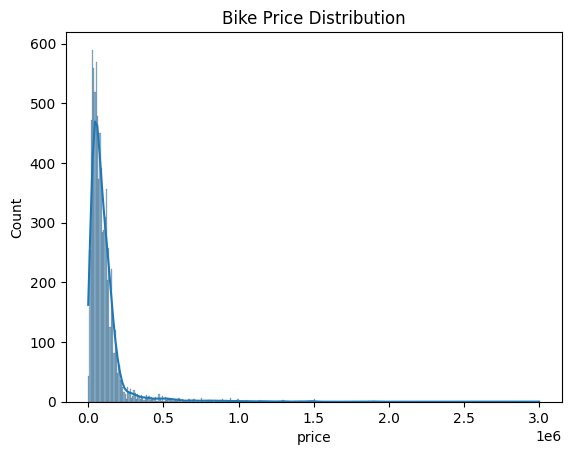

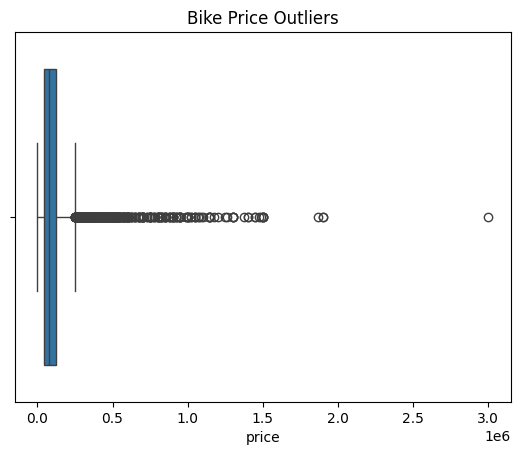

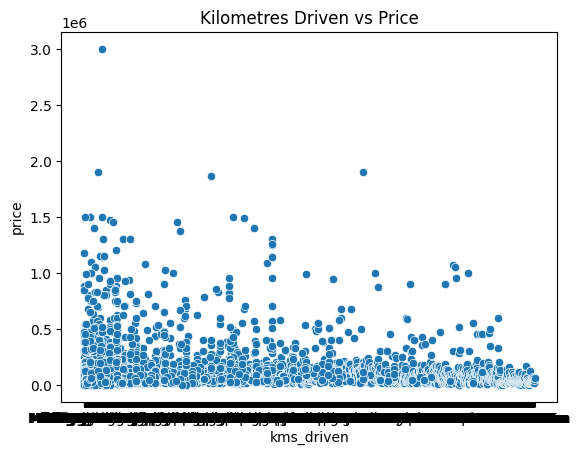

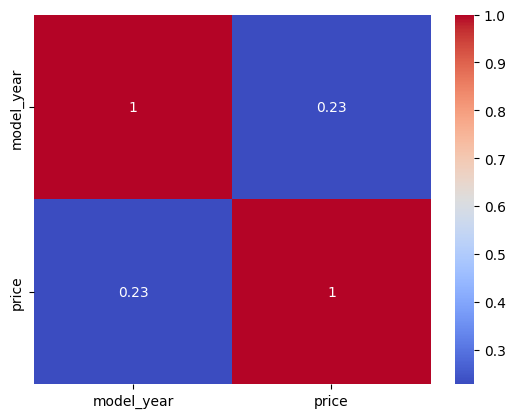

In [2]:
print(df.head())
print(df.tail())
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.dtypes)
df.info()

print("Missing values:\n", df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df.describe())

# Numerical and categorical columns
print("Numerical:", df.select_dtypes(include='number').columns.tolist())
print("Categorical:", df.select_dtypes(include='object').columns.tolist())

# Price distribution
sns.histplot(df['price'], kde=True)
plt.title("Bike Price Distribution")
plt.show()

# Boxplot
sns.boxplot(x=df['price'])
plt.title("Bike Price Outliers")
plt.show()

# Price vs kilometres driven
sns.scatterplot(data=df, x='kms_driven', y='price')
plt.title("Kilometres Driven vs Price")
plt.show()

# Correlation heatmap
sns.heatmap(df.select_dtypes(include='number').corr(),
            annot=True, cmap='coolwarm')
plt.show()

2. Probability Distributions

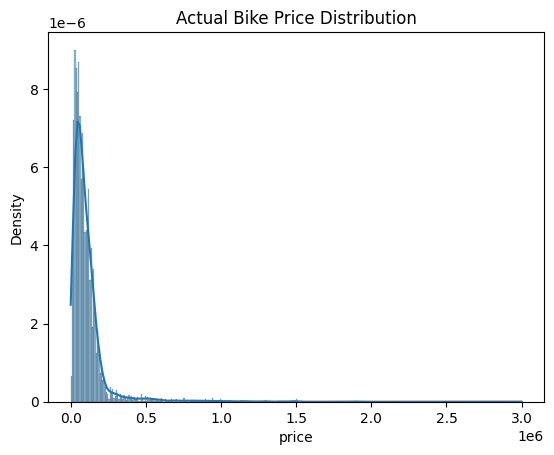

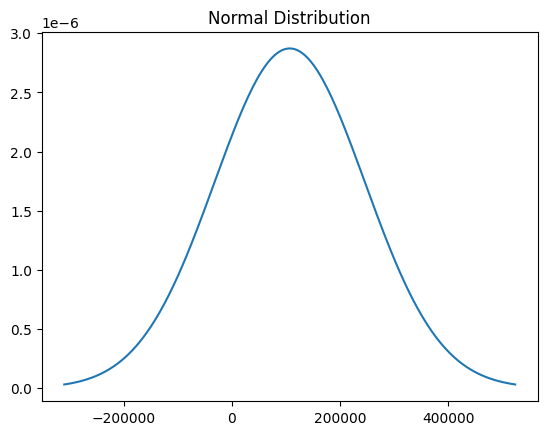

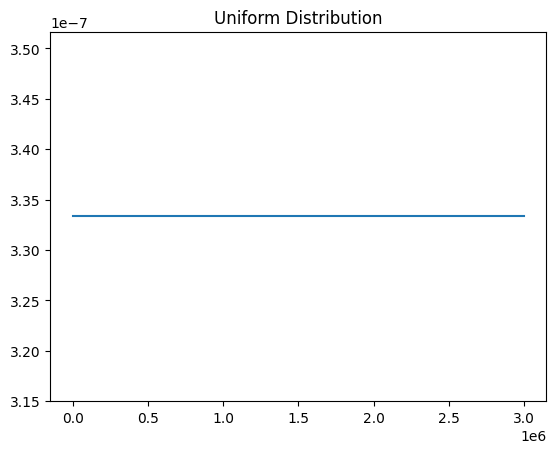

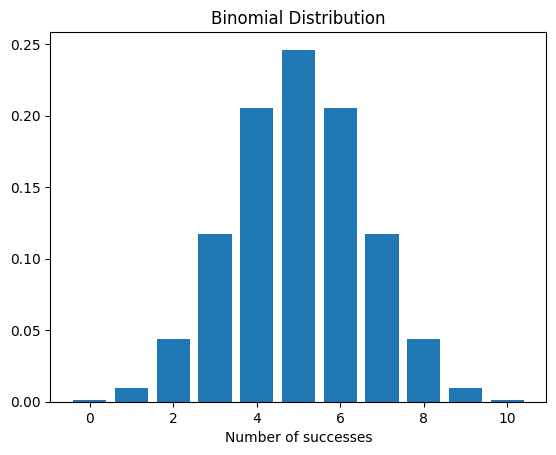

In [3]:
from scipy.stats import norm, uniform, binom

x = df['price'].dropna()
mean, sd = x.mean(), x.std()

# Actual price distribution
sns.histplot(x, stat='density', kde=True)
plt.title("Actual Bike Price Distribution")
plt.show()

# Normal distribution
values = np.linspace(mean - 3*sd, mean + 3*sd, 200)
plt.plot(values, norm.pdf(values, mean, sd))
plt.title("Normal Distribution")
plt.show()

# Uniform distribution
values = np.linspace(x.min(), x.max(), 200)
plt.plot(values, uniform.pdf(values, x.min(), x.max()-x.min()))
plt.title("Uniform Distribution")
plt.show()

# Binomial distribution
k = np.arange(11)
plt.bar(k, binom.pmf(k, 10, 0.5))
plt.title("Binomial Distribution")
plt.xlabel("Number of successes")
plt.show()

3.Sampling Techniques

In [4]:
# 1. Simple Random Sampling
srs = df.sample(n=min(100, len(df)), random_state=42)

# 2. Systematic Sampling
systematic = df.iloc[::max(1, len(df)//100)]

# 3. Stratified Sampling by owner
stratified = df.groupby('owner', group_keys=False).sample(
    frac=0.2, random_state=42
) if 'owner' in df.columns else srs

# 4. Cluster Sampling by location
if 'location' in df.columns:
    locations = df['location'].dropna().unique()
    cluster = df[df['location'] == locations[0]]
else:
    cluster = srs

# Compare samples
for name, sample in {
    'Random': srs,
    'Systematic': systematic,
    'Stratified': stratified,
    'Cluster': cluster
}.items():
    print("\n", name)
    print("Sample size:", len(sample))
    print("Mean price:", sample['price'].mean())
    print("Variance:", sample['price'].var())
    print("Standard deviation:", sample['price'].std())


 Random
Sample size: 100
Mean price: 101392.5
Variance: 9851034798.69697
Standard deviation: 99252.3793100043

 Systematic
Sample size: 101
Mean price: 123945.46534653465
Variance: 23290676606.77129
Standard deviation: 152612.83237910006

 Stratified
Sample size: 1572
Mean price: 108934.54580152672
Variance: 21373727475.839462
Standard deviation: 146197.56316655714

 Cluster
Sample size: 337
Mean price: 106723.83976261127
Variance: 11956129448.373056
Standard deviation: 109344.08739558375


4. CLT

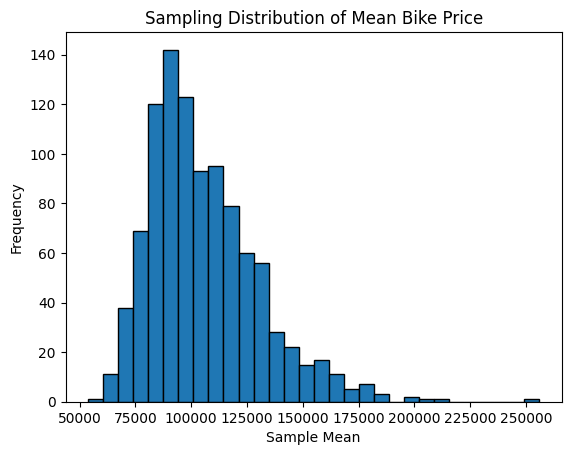

Population Mean: 106791.33689703449
Mean of Sample Means: 105787.49986666668


In [5]:
prices = df['price'].dropna()
sample_means = []

for i in range(1000):
    sample = prices.sample(n=min(30, len(prices)), replace=True)
    sample_means.append(sample.mean())

plt.hist(sample_means, bins=30, edgecolor='black')
plt.title("Sampling Distribution of Mean Bike Price")
plt.xlabel("Sample Mean")
plt.ylabel("Frequency")
plt.show()

print("Population Mean:", prices.mean())
print("Mean of Sample Means:", np.mean(sample_means))

5.Confidence Interval, Z-Test and One-Sample t-Test

In [6]:
from scipy import stats

x = df['price'].dropna()
n = len(x)
mean = x.mean()
sd = x.std(ddof=1)

# 95% Confidence Interval
ci = stats.t.interval(
    0.95, df=n-1, loc=mean, scale=stats.sem(x)
)
print("Mean Price:", mean)
print("95% Confidence Interval:", ci)

# Hypothesized mean price (change if required)
hyp_mean = 100000

# Large-sample Z-test approximation
z = (mean - hyp_mean) / (sd / np.sqrt(n))
p_z = 2 * stats.norm.sf(abs(z))
print("Z statistic:", z)
print("Z-test p-value:", p_z)

# One-sample t-test
t_stat, p_t = stats.ttest_1samp(x, popmean=hyp_mean)
print("T statistic:", t_stat)
print("T-test p-value:", p_t)

Mean Price: 106791.33689703449
95% Confidence Interval: (np.float64(103718.9878654254), np.float64(109863.68592864358))
Z statistic: 4.333110162396124
Z-test p-value: 1.4701749691454316e-05
T statistic: 4.3331101623961255
T-test p-value: 1.4884772045256429e-05


6.Hypothesis Testing, Correlation and Two-Way ANOVA

In [7]:
from scipy.stats import chi2_contingency, pearsonr, spearmanr
from statsmodels.formula.api import ols
import statsmodels.api as sm
import pandas as pd
import numpy as np

# Helper function to clean text columns to numeric values
def clean_numeric(val):
    if pd.isna(val) or not isinstance(val, str):
        return val
    # Remove common units/strings
    clean_val = val.lower().replace('km', '').replace('kmpl', '').replace('bhp', '').replace('mileage', '').strip()
    try:
        return float(clean_val)
    except ValueError:
        return np.nan

# Create a copy of the dataframe to clean columns
cleaned_df = df.copy()
for col in ['kms_driven', 'mileage', 'power']:
    if col in cleaned_df.columns:
        cleaned_df[col] = cleaned_df[col].apply(clean_numeric)

# 1. Chi-square test: Owner vs Price Segment
if 'owner' in cleaned_df.columns:
    # Dynamically create price_segment if it doesn't exist
    if 'price_segment' not in cleaned_df.columns and 'price' in cleaned_df.columns:
        cleaned_df['price_segment'] = pd.qcut(
            cleaned_df['price'],
            q=3,
            labels=['Low', 'Medium', 'High'],
            duplicates='drop'
        )

    if 'price_segment' in cleaned_df.columns:
        table = pd.crosstab(cleaned_df['owner'], cleaned_df['price_segment'])
        chi2, p, dof, expected = chi2_contingency(table)
        print("Chi-square:", chi2)
        print("Chi-square p-value:", p)

# 2. Covariance and Correlation using cleaned columns
for col in ['kms_driven', 'mileage', 'power']:
    if col in cleaned_df.columns:
        data = cleaned_df[[col, 'price']].dropna()
        print(f"\n{col} vs price")
        print("Covariance:", data[col].cov(data['price']))
        print("Pearson:", pearsonr(data[col], data['price']))
        print("Spearman:", spearmanr(data[col], data['price']))

# 3. Two-Way ANOVA: Owner and Model Year Group
if 'owner' in cleaned_df.columns and 'model_year' in cleaned_df.columns:
    anova_df = cleaned_df[['price', 'owner', 'model_year']].dropna().copy()

    anova_df['year_group'] = pd.qcut(
        anova_df['model_year'],
        q=3,
        labels=['Older', 'Middle', 'Newer'],
        duplicates='drop'
    )

    formula = 'price ~ C(owner) * C(year_group)'
    anova_model = ols(formula, data=anova_df).fit()
    print(sm.stats.anova_lm(anova_model, typ=2))

Chi-square: 81.74117060557171
Chi-square p-value: 1.5601489072779677e-15

kms_driven vs price
Covariance: -851461748.1776936
Pearson: PearsonRResult(statistic=np.float64(-0.19920011368525775), pvalue=np.float64(1.3583166385926e-53))
Spearman: SignificanceResult(statistic=np.float64(-0.5315685959336864), pvalue=np.float64(0.0))

mileage vs price
Covariance: 0.0
Pearson: PearsonRResult(statistic=np.float64(nan), pvalue=np.float64(nan))
Spearman: SignificanceResult(statistic=nan, pvalue=nan)

power vs price
Covariance: 1717891.162849342
Pearson: PearsonRResult(statistic=np.float64(0.8331102216369775), pvalue=np.float64(0.0))
Spearman: SignificanceResult(statistic=np.float64(0.7619780734197795), pvalue=np.float64(0.0))
                              sum_sq      df           F        PR(>F)
C(owner)                2.131819e+11     3.0    3.889294  8.643589e-03
C(year_group)           7.652856e+12     2.0  209.428233  2.462868e-89
C(owner):C(year_group)  2.659837e+11     6.0    2.426305  2.40

/tmp/ipykernel_7361/3633005855.py:47: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  print("Pearson:", pearsonr(data[col], data['price']))
/tmp/ipykernel_7361/3633005855.py:48: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  print("Spearman:", spearmanr(data[col], data['price']))


7. Regression Models and Model Selection

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Select available input features
features = [
    c for c in [
        'model_name', 'model_year', 'kms_driven',
        'owner', 'location', 'mileage', 'power'
    ] if c in df.columns
]

X = df[features]
y = df['price']

num = X.select_dtypes(include='number').columns.tolist()
cat = [c for c in features if c not in num]

preprocessor = ColumnTransformer([
    ('num', make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler()
    ), num),
    ('cat', make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore')
    ), cat)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

models = {
    'Linear Regression': LinearRegression(),
    'Ridge': Ridge(),
    'Lasso': Lasso(max_iter=10000),
    'Decision Tree': DecisionTreeRegressor(random_state=42),
    'Random Forest': RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    )
}

results = {}

for name, regressor in models.items():
    pipeline = make_pipeline(preprocessor, regressor)
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    results[name] = {
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    }

print(pd.DataFrame(results).T.sort_values('RMSE'))

                            MAE           RMSE        R2
Ridge              23895.628422   90402.106169  0.616245
Linear Regression  25007.317104   92861.458630  0.595081
Lasso              22163.472201   96920.917846  0.558905
Random Forest      20970.725010   98044.807340  0.548616
Decision Tree      22983.463348  101514.322996  0.516105


8. Classification and Model Comparison

In [9]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# Create the price segment column in df if it doesn't exist
if 'price_segment' not in df.columns:
    df['price_segment'] = pd.qcut(
        df['price'],
        q=3,
        labels=['Low', 'Medium', 'High'],
        duplicates='drop'
    )

# Target: price category
X = df[features]
y = df['price_segment']

num = X.select_dtypes(include='number').columns.tolist()
cat = [c for c in features if c not in num]

preprocessor = ColumnTransformer([
    ('num', make_pipeline(
        SimpleImputer(strategy='median'),
        StandardScaler()
    ), num),
    ('cat', make_pipeline(
        SimpleImputer(strategy='most_frequent'),
        OneHotEncoder(handle_unknown='ignore')
    ), cat)
])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

models = {
    'Logistic Regression': LogisticRegression(max_iter=1000),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(
        n_estimators=100, random_state=42, n_jobs=-1
    )
}

results = {}

for name, classifier in models.items():
    pipeline = make_pipeline(preprocessor, classifier)
    pipeline.fit(X_train, y_train)
    pred = pipeline.predict(X_test)

    results[name] = {
        'Accuracy': accuracy_score(y_test, pred),
        'Precision': precision_score(
            y_test, pred, average='weighted', zero_division=0
        ),
        'Recall': recall_score(
            y_test, pred, average='weighted', zero_division=0
        ),
        'F1 Score': f1_score(
            y_test, pred, average='weighted', zero_division=0
        )
    }

    print('\n', name)
    print('Confusion Matrix:\n', confusion_matrix(y_test, pred))
    print(classification_report(y_test, pred, zero_division=0))

print("\nModel Comparison:")
print(pd.DataFrame(results).T.sort_values('F1 Score', ascending=False))


 Logistic Regression
Confusion Matrix:
 [[471   8  44]
 [  9 475  45]
 [ 65  67 388]]
              precision    recall  f1-score   support

        High       0.86      0.90      0.88       523
         Low       0.86      0.90      0.88       529
      Medium       0.81      0.75      0.78       520

    accuracy                           0.85      1572
   macro avg       0.85      0.85      0.85      1572
weighted avg       0.85      0.85      0.85      1572


 Decision Tree
Confusion Matrix:
 [[454  10  59]
 [  4 466  59]
 [ 56  65 399]]
              precision    recall  f1-score   support

        High       0.88      0.87      0.88       523
         Low       0.86      0.88      0.87       529
      Medium       0.77      0.77      0.77       520

    accuracy                           0.84      1572
   macro avg       0.84      0.84      0.84      1572
weighted avg       0.84      0.84      0.84      1572


 Random Forest
Confusion Matrix:
 [[468   8  47]
 [  6 476  47]
 [ 66

In [10]:
%%writefile app.py

import streamlit as st
import pandas as pd
import numpy as np
import requests
from io import BytesIO

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

st.set_page_config(page_title="Bike Price Prediction", page_icon="🏍️")

st.title("🏍️ Used Bike Price Prediction")
st.write("Enter the bike details to estimate its price.")


# Load dataset automatically
@st.cache_data
def load_data():
    url = "https://raw.githubusercontent.com/KrutinBhat/Used-Bike-Prices-Analysis/main/bikes.csv"

    response = requests.get(url, timeout=30)
    response.raise_for_status()

    data = pd.read_csv(BytesIO(response.content))
    data.columns = data.columns.str.strip().str.lower()

    for col in ["model_year", "kms_driven", "mileage", "power", "price"]:
        if col in data.columns:
            data[col] = pd.to_numeric(
                data[col].astype(str)
                .str.replace(",", "", regex=False)
                .str.extract(r"([-+]?\d*\.?\d+)")[0],
                errors="coerce"
            )

    data = data.drop_duplicates()
    data = data.dropna(subset=["price"])
    data = data[data["price"] > 0]

    return data


# Train model
@st.cache_resource
def train_model():
    data = load_data()

    features = [
        col for col in [
            "model_name", "model_year", "kms_driven",
            "owner", "location", "mileage", "power"
        ]
        if col in data.columns
    ]

    if not features:
        raise ValueError("No expected input features found in the dataset.")

    X = data[features]
    y = data["price"]

    numerical = X.select_dtypes(include="number").columns.tolist()
    categorical = [c for c in features if c not in numerical]

    preprocessing = ColumnTransformer([
        ("num", make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler()
        ), numerical),

        ("cat", make_pipeline(
            SimpleImputer(strategy="most_frequent"),
            OneHotEncoder(handle_unknown="ignore")
        ), categorical)
    ])

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = make_pipeline(
        preprocessing,
        RandomForestRegressor(
            n_estimators=100,
            random_state=42,
            n_jobs=-1
        )
    )

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    metrics = {
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "R2": r2_score(y_test, predictions)
    }

    return data, features, numerical, categorical, model, metrics


# Handle data and model errors
try:
    data, features, numerical, categorical, model, metrics = train_model()
except Exception as e:
    st.error(f"Unable to load the dataset or train the model: {e}")
    st.stop()


# User input form
st.subheader("Enter Bike Details")

with st.form("bike_form"):
    values = {}
    columns = st.columns(2)

    for i, col in enumerate(features):
        with columns[i % 2]:
            label = col.replace("_", " ").title()

            if col in numerical:
                median = data[col].median()
                values[col] = st.number_input(
                    label,
                    value=float(median) if pd.notna(median) else 0.0
                )
            else:
                options = sorted(
                    data[col].dropna().astype(str).unique().tolist()
                )

                if options:
                    values[col] = st.selectbox(label, options)
                else:
                    values[col] = st.text_input(label)

    submit = st.form_submit_button("Predict Bike Price")


# Display prediction
if submit:
    input_data = pd.DataFrame([values], columns=features)

    for col in categorical:
        input_data[col] = input_data[col].astype(str)

    price = model.predict(input_data)[0]

    st.success(f"Estimated Bike Price: ₹{price:,.0f}")
    st.caption(
        "This estimate is based on historical listings and may not "
        "represent the current market price."
    )


# Model evaluation
st.subheader("Model Evaluation")

col1, col2, col3 = st.columns(3)

col1.metric("MAE", f"₹{metrics['MAE']:,.0f}")
col2.metric("RMSE", f"₹{metrics['RMSE']:,.0f}")
col3.metric("R² Score", f"{metrics['R2']:.3f}")

st.write("Number of records:", len(data))
st.write("Features used:", features)

Writing app.py


In [11]:
!pip install -q streamlit
!npm install -g localtunnel

⠙⠹⠸⠼⠴⠦⠧⠇⠏⠋⠙⠹⠸⠼⠴⠦⠧
added 22 packages in 2s
⠧
⠧3 packages are looking for funding
⠧  run `npm fund` for details
⠧

In [12]:
!streamlit run app.py --server.port 8501 --server.address 0.0.0.0 > streamlit.log 2>&1 &

In [ ]:
!lt --port 8501

your url is: https://five-pugs-smash.loca.lt
